# Feature selection with a QUBO and D-Wave quantum annealing

## Part 2 — Select features, train a classifier, and measure the results

**Correlation inputs → QUBO → D-Wave QPU → Feature subset → Classifier → Comparison**

This continues Part 1's **Pearson correlation** experiment. The reference paper uses mutual/conditional mutual information; this notebook implements a relevance–redundancy surrogate, rather than reproducing that paper's MIQUBO or classical CFS's ratio-based merit.

We will compare:

1. Logistic regression with all eight features.
2. Logistic regression with the top-$k$ individual correlation scores.
3. The same QUBO solved exactly on a CPU.
4. The same QUBO solved by classical simulated annealing.
5. The same QUBO sampled directly on an actual D-Wave QPU.

All approaches use the same held-out test rows, classifier settings, and decision threshold. Hyperparameters are chosen on training data only. A majority-class classifier is included as an additional reference.

Run the cells from top to bottom. The first QPU run uses `DWAVE_API_TOKEN` from the environment or the repository's `.env`. Identical later runs reuse the saved QPU response by default; changing parameters or disabling the cache submits a new hardware job. Classical simulated annealing is not a quantum run.

## 0. Environment and experiment configuration

Choose the repository's `.venv` Python kernel. If needed, install the requirements file in this notebook's folder, then restart the kernel:

```python
%pip install -r requirements.txt
```

The classifier is logistic regression with `C=1`, training-fitted median imputation and standardization, and a fixed 0.5 decision threshold. We tune the selector's $k$ and $\alpha$ by five-fold stratified cross-validation on the 80% training partition. The primary tuning metric is F1 for the positive class, with fewer features preferred when mean F1 ties.

In [1]:
from pathlib import Path
from itertools import product
from time import perf_counter
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json
import os
import sys
import tempfile

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "pima-matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from dotenv import dotenv_values
import dimod
from dwave.samplers import SimulatedAnnealingSampler
from dwave.system import DWaveSampler, EmbeddingComposite

# Tiny models are more predictable with one CPU math thread.
CPU_THREAD_LIMIT = threadpool_limits(limits=1)

PROJECT_DIR = None
for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    for candidate in [parent, parent / "Quantum annealing for feature selection"]:
        if (candidate / "skill.md").is_file() and (candidate / "data/raw/pima-indians-diabetes.csv").is_file():
            PROJECT_DIR = candidate
            break
    if PROJECT_DIR is not None:
        break
if PROJECT_DIR is None:
    raise FileNotFoundError("Run Part 1 first, then launch this notebook from this project.")

OUTPUT_DIR = PROJECT_DIR / "outputs" / "qubo"
QPU_CACHE_DIR = OUTPUT_DIR / "qpu_runs"
QPU_CACHE_DIR.mkdir(parents=True, exist_ok=True)
FEATURES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
K_VALUES = list(range(1, 9))
ALPHA_VALUES = [0.25, 0.50, 0.75]
NUM_READS = 1000
RUN_QPU = True
USE_QPU_CACHE = True
VERSIONS = {name: version(name) for name in [
    "numpy", "pandas", "scikit-learn", "dimod", "dwave-system", "dwave-samplers",
]}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 15)
print("Project:", PROJECT_DIR)
print("Cross-validation:", CV_FOLDS, "folds; QPU reads:", NUM_READS)
display(pd.Series(VERSIONS, name="version").to_frame())

Project: /Users/maishachowa/Maisha/Research/Quantum-Computing/Quantum annealing for feature selection
Cross-validation: 5 folds; QPU reads: 1000


,version
numpy,2.5.1
pandas,3.0.1
scikit-learn,1.9.1
dimod,0.12.22
dwave-system,1.35.0
dwave-samplers,1.8.0


## 1. Reconstruct the original split without leaking validation information

Reload the original data so each cross-validation fold can learn its **own** imputation medians and correlation scores. Reusing the already-imputed full-training data inside cross-validation would leak information from the validation rows.

The full-training arrays from Part 1 are checked for consistency later; they are not used to calculate validation-fold scores. The held-out test partition is used only after choosing selector parameters.

In [2]:
RAW_PATH = PROJECT_DIR / "data/raw/pima-indians-diabetes.csv"
EXPECTED_SHA256 = "6bfe5d0f379d17a0e0819b996407e3c09bf80febd4287f2ed212190dfff154af"
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == EXPECTED_SHA256
raw = pd.read_csv(RAW_PATH, header=None, names=FEATURES + ["Outcome"])
raw.index.name = "record_id"
assert raw.shape == (768, 9)
assert raw.Outcome.value_counts().to_dict() == {0: 500, 1: 268}
X = raw[FEATURES].copy()
X[ZERO_AS_MISSING] = X[ZERO_AS_MISSING].replace(0, np.nan)
y = raw["Outcome"].astype(int)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE,
)
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)
assert X_train_raw.index.equals(y_train.index)
assert X_test_raw.index.equals(y_test.index)
print("Training rows:", len(X_train_raw), "| Test rows:", len(X_test_raw))
print("All selection and tuning calculations below use training rows.")

Training rows: 614 | Test rows: 154
All selection and tuning calculations below use training rows.


### 1.1 Reusable training-only correlation calculation

The function returns the fitted imputer, relevance vector, and zero-diagonal redundancy matrix in the original feature order. Each validation fold calls it with that fold's training rows only.

In [3]:
def correlation_inputs(X_fit, y_fit):
    if not X_fit.index.equals(y_fit.index):
        raise ValueError("Predictors and labels are misaligned.")
    if X_fit.isna().all().any():
        raise ValueError("A predictor has no observed training values.")
    imputer = SimpleImputer(strategy="median")
    imputed = pd.DataFrame(imputer.fit_transform(X_fit), columns=FEATURES, index=X_fit.index)
    if imputed.nunique().le(1).any() or y_fit.nunique() != 2:
        raise ValueError("Correlation requires varying predictors and both target classes.")
    relevance = imputed.corrwith(y_fit).abs().reindex(FEATURES).to_numpy(dtype=float)
    redundancy = imputed.corr().abs().loc[FEATURES, FEATURES].to_numpy(dtype=float, copy=True)
    np.fill_diagonal(redundancy, 0.0)
    assert np.isfinite(relevance).all() and np.isfinite(redundancy).all()
    np.testing.assert_allclose(redundancy, redundancy.T, atol=1e-12)
    return imputer, relevance, redundancy

def classifier():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, random_state=RANDOM_STATE),
    )

cv = list(StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(
    X_train_raw, y_train,
))

## 2. Formulate feature selection as a QUBO

Use one binary variable $x_i$ for each predictor: $x_i=1$ selects that feature.

$$
E(x)= -\alpha\sum_i r_i x_i
+(1-\alpha)\sum_{i<j}R_{ij}x_ix_j
+A\left(\sum_i x_i-k\right)^2.
$$

- $r_i=|\operatorname{corr}(X_i,y)|$: reward target relevance.
- $R_{ij}=|\operatorname{corr}(X_i,X_j)|$ for distinct features: penalize redundancy.
- $k$: requested number of features.
- $A$: penalty that makes the globally optimal solution obey the requested size.
- $\alpha$: balances the raw relevance and redundancy sums. The terms have different numbers of contributions, so $\alpha=0.5$ does not necessarily make their numerical contributions equal.

Ocean minimizes energy. Expanding the square and using $x_i^2=x_i$ gives the **upper-triangular** coefficients:

$$Q_{ii}=-\alpha r_i+A(1-2k),\qquad Q_{ij}=(1-\alpha)R_{ij}+2A\quad(i<j).$$

The constant offset is $Ak^2$. We keep it in the BQM so its energy agrees with the original formula. Count each pair once. This is not an exact reformulation of Hall's ratio-based CFS merit or of the paper's MI/CMI objective.

### 2.1 Choose a sufficient size penalty

Use the conservative bound

$$A>\max_i\left[\alpha r_i+(1-\alpha)\sum_j R_{ij}\right].$$

The bracket bounds the change in the unpenalized objective from flipping one bit. Whenever a solution has the wrong number of selected features, one flip toward $k$ reduces the size penalty by at least $A$, exceeding any possible increase in the unpenalized objective. Therefore a global minimum must have exactly $k$ ones. We add a small margin of 0.1 and verify feasibility exhaustively.

Large penalties can reduce effective hardware precision for the smaller correlation terms. This sufficient bound is a transparent starting point, rather than a claim that it is the best hardware calibration.

In [4]:
def build_qubo(relevance, redundancy, alpha, k):
    n = len(relevance)
    if not 0 < alpha < 1 or not 1 <= k <= n:
        raise ValueError("Require 0 < alpha < 1 and 1 <= k <= number of features.")
    penalty = float(np.max(alpha * relevance + (1 - alpha) * redundancy.sum(axis=1)) + 0.1)
    Q = {(i, i): float(-alpha * relevance[i] + penalty * (1 - 2*k)) for i in range(n)}
    for i in range(n):
        for j in range(i + 1, n):
            Q[i, j] = float((1 - alpha) * redundancy[i, j] + 2*penalty)
    bqm = dimod.BinaryQuadraticModel.from_qubo(Q, offset=penalty*k*k)
    return bqm, Q, penalty

def original_energy(bits, relevance, redundancy, alpha, k, penalty):
    bits = np.asarray(bits, dtype=float)
    relevance_term = -alpha * np.dot(relevance, bits)
    redundancy_term = (1 - alpha) * np.sum(np.triu(redundancy, k=1) * np.outer(bits, bits))
    return float(relevance_term + redundancy_term + penalty * (bits.sum() - k)**2)

def best_feasible(sampleset, k):
    # Always choose by QUBO energy, never by held-out classifier performance.
    candidates = []
    for row in sampleset.data(fields=["sample", "energy"]):
        bits = tuple(int(row.sample[i]) for i in range(len(FEATURES)))
        if sum(bits) == k:
            candidates.append((float(row.energy), bits))
    if not candidates:
        return None
    _, bits = min(candidates, key=lambda item: (round(item[0], 12), item[1]))
    return np.asarray(bits, dtype=int)

## 3. Choose selector settings using training-only cross-validation

For each of five folds:

1. Fit medians and calculate correlations on the fold's training rows.
2. Construct a QUBO for each candidate $(k,\alpha)$.
3. Solve its 256 assignments exactly to choose the subset.
4. Fit the classifier on the fold's training rows with that subset.
5. Score the untouched validation rows.

Exact selection is practical for eight variables and lets us tune a common objective before comparing solvers. These validation scores describe the **exact-QUBO selector**, not a cross-validated QPU result. Final hardware results will be evaluated once with the frozen parameters.

The top-$k$ baseline separately chooses its best $k$ using the same folds, avoiding an arbitrary disadvantage in the main classifier comparison. A matched-$k$ top-correlation baseline is also reported to compare methods at the QUBO's chosen size. Tuning time is recorded separately from final-run timings.

In [5]:
tuning_start = perf_counter()
cv_rows = []
topk_cv_rows = []
all_features_cv_rows = []
for fold, (fit_indices, validation_indices) in enumerate(cv, start=1):
    X_fit = X_train_raw.iloc[fit_indices]
    y_fit = y_train.iloc[fit_indices]
    X_validation = X_train_raw.iloc[validation_indices]
    y_validation = y_train.iloc[validation_indices]
    assert set(X_fit.index).isdisjoint(X_validation.index)
    fold_imputer, fold_r, fold_R = correlation_inputs(X_fit, y_fit)
    np.testing.assert_allclose(fold_imputer.statistics_, X_fit.median().to_numpy())

    all_model = classifier().fit(X_fit, y_fit)
    all_prediction = all_model.predict(X_validation)
    all_features_cv_rows.append({"fold": fold, "f1": f1_score(y_validation, all_prediction, zero_division=0),
                                 "accuracy": accuracy_score(y_validation, all_prediction)})

    relevance_order = np.argsort(-fold_r, kind="stable")
    for k in K_VALUES:
        top_features = [FEATURES[i] for i in relevance_order[:k]]
        top_model = classifier().fit(X_fit[top_features], y_fit)
        prediction = top_model.predict(X_validation[top_features])
        topk_cv_rows.append({"fold": fold, "k": k,
                            "f1": f1_score(y_validation, prediction, zero_division=0),
                            "accuracy": accuracy_score(y_validation, prediction)})
        for alpha in ALPHA_VALUES:
            fold_bqm, _, _ = build_qubo(fold_r, fold_R, alpha, k)
            exact_fold = dimod.ExactSolver().sample(fold_bqm)
            assert sum(exact_fold.first.sample.values()) == k
            bits = best_feasible(exact_fold, k)
            chosen = [FEATURES[i] for i in np.flatnonzero(bits)]
            model = classifier().fit(X_fit[chosen], y_fit)
            prediction = model.predict(X_validation[chosen])
            cv_rows.append({"fold": fold, "k": k, "alpha": alpha,
                            "f1": f1_score(y_validation, prediction, zero_division=0),
                            "accuracy": accuracy_score(y_validation, prediction),
                            "features": ", ".join(chosen)})

tuning_wall_s = perf_counter() - tuning_start
cv_details = pd.DataFrame(cv_rows)
cv_summary = cv_details.groupby(["k", "alpha"], as_index=False).agg(
    mean_f1=("f1", "mean"), std_f1=("f1", "std"), mean_accuracy=("accuracy", "mean"),
).sort_values(["mean_f1", "k", "alpha"], ascending=[False, True, True], ignore_index=True)
topk_cv_summary = pd.DataFrame(topk_cv_rows).groupby("k", as_index=False).agg(
    mean_f1=("f1", "mean"), std_f1=("f1", "std"), mean_accuracy=("accuracy", "mean"),
).sort_values(["mean_f1", "k"], ascending=[False, True], ignore_index=True)
selected_k = int(cv_summary.iloc[0]["k"])
selected_alpha = float(cv_summary.iloc[0]["alpha"])
topk_selected_k = int(topk_cv_summary.iloc[0]["k"])
display(cv_summary.round(4))
display(topk_cv_summary.round(4))
print(f"Frozen QUBO settings: k={selected_k}, alpha={selected_alpha}")
print(f"Top-correlation baseline's independently selected k: {topk_selected_k}")
print(f"Shared classical parameter-search wall time: {tuning_wall_s:.3f} seconds")

,k,alpha,mean_f1,std_f1,mean_accuracy
0,4,0.50,0.6685,0.0211,0.7947
1,4,0.75,0.6685,0.0211,0.7947
2,5,0.75,0.6616,0.0207,0.7899
3,6,0.75,0.6615,0.0275,0.7898
4,6,0.50,0.6578,0.0270,0.7866
5,7,0.75,0.6565,0.0248,0.7882
6,3,0.50,0.6553,0.0345,0.7850
7,3,0.75,0.6553,0.0345,0.7850
8,8,0.25,0.6545,0.0273,0.7882
9,8,0.50,0.6545,0.0273,0.7882


,k,mean_f1,std_f1,mean_accuracy
0,8,0.6545,0.0273,0.7882
1,7,0.6515,0.0247,0.7834
2,6,0.6495,0.0378,0.7817
3,2,0.6446,0.0358,0.7801
4,5,0.6410,0.0384,0.7752
5,3,0.6405,0.0387,0.7801
6,4,0.6356,0.0447,0.7752
7,1,0.5893,0.0371,0.7524


Frozen QUBO settings: k=4, alpha=0.5
Top-correlation baseline's independently selected k: 8
Shared classical parameter-search wall time: 0.803 seconds


## 4. Construct and verify the final training QUBO

Refit the correlation calculation on all 614 training rows after freezing the settings. Verify it agrees with Part 1's saved inputs when they are available. Enumerate every binary assignment and compare the expanded BQM energy to the original mathematical expression.

In [6]:
score_start = perf_counter()
training_imputer, relevance, redundancy = correlation_inputs(X_train_raw, y_train)
score_preparation_s = perf_counter() - score_start
part1_inputs = PROJECT_DIR / "outputs/correlation_inputs.npz"
if part1_inputs.exists():
    with np.load(part1_inputs, allow_pickle=False) as previous:
        assert previous["feature_names"].tolist() == FEATURES
        np.testing.assert_allclose(previous["relevance"], relevance, atol=1e-12)
        np.testing.assert_allclose(previous["redundancy"], redundancy, atol=1e-12)
    print("Final training correlations agree with Part 1.")

qubo_start = perf_counter()
bqm, Q, penalty = build_qubo(relevance, redundancy, selected_alpha, selected_k)
qubo_build_s = perf_counter() - qubo_start
Q_display = pd.DataFrame(0.0, index=FEATURES, columns=FEATURES)
for (i, j), coefficient in Q.items():
    Q_display.iloc[i, j] = coefficient
display(Q_display.round(4))
print(f"Penalty A: {penalty:.6f}; BQM offset: {bqm.offset:.6f}")

assignments = np.asarray(list(product([0, 1], repeat=len(FEATURES))), dtype=int)
direct_energies = np.asarray([
    original_energy(bits, relevance, redundancy, selected_alpha, selected_k, penalty)
    for bits in assignments
])
np.testing.assert_allclose(bqm.energies((assignments, list(range(8)))), direct_energies, atol=1e-10)
ground_mask = np.isclose(direct_energies, direct_energies.min(), atol=1e-9, rtol=0)
assert np.all(assignments[ground_mask].sum(axis=1) == selected_k)
print("Verified all 256 energies and feasibility of every exact ground state.")

Final training correlations agree with Part 1.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Pregnancies,-8.4997,2.4677,2.4999,2.4418,2.4308,2.4055,2.4247,2.6667
Glucose,0.0000,-8.6517,2.5083,2.5107,2.6241,2.5116,2.4683,2.5435
BloodPressure,0.0000,0.0000,-8.4873,2.4890,2.4411,2.5335,2.4012,2.5563
SkinThickness,0.0000,0.0000,0.0000,-8.5127,2.5100,2.6680,2.4535,2.4665
Insulin,0.0000,0.0000,0.0000,0.0000,-8.5185,2.5014,2.4943,2.4598
BMI,0.0000,0.0000,0.0000,0.0000,0.0000,-8.5600,2.4805,2.4129
DiabetesPedigreeFunction,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-8.4782,2.4113
Age,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-8.5159


Penalty A: 1.199366; BQM offset: 19.189861
Verified all 256 energies and feasibility of every exact ground state.


### 4.1 Check the formulation on a small, understandable example

With two equally redundant-free features and $k=1$, a feature with relevance 0.9 should beat one with relevance 0.2. This checks that the signs reward relevance and that the size penalty does not select both.

In [7]:
toy_bqm, _, toy_penalty = build_qubo(np.array([0.9, 0.2]), np.zeros((2, 2)), alpha=0.5, k=1)
toy_samples = dimod.ExactSolver().sample(toy_bqm)
assert dict(toy_samples.first.sample) == {0: 1, 1: 0}
for toy_bits in product([0, 1], repeat=2):
    np.testing.assert_allclose(
        toy_bqm.energy(dict(enumerate(toy_bits))),
        original_energy(toy_bits, np.array([0.9, 0.2]), np.zeros((2, 2)), 0.5, 1, toy_penalty),
        atol=1e-12,
    )
print("Toy problem chooses the more relevant feature and obeys k=1.")

Toy problem chooses the more relevant feature and obeys k=1.


## 5. Solve the QUBO with classical baselines

Exact solving establishes the reference optimum. Simulated annealing is a classical heuristic run locally with 1,000 reads, 1,000 sweeps per read, and a fixed seed. For each method we keep the lowest-energy returned sample satisfying the frozen size constraint.

In [8]:
start = perf_counter()
exact_samples = dimod.ExactSolver().sample(bqm)
exact_samples.resolve()
exact_wall_s = perf_counter() - start
exact_bits = best_feasible(exact_samples, selected_k)
exact_optimum = float(exact_samples.first.energy)
np.testing.assert_allclose(exact_optimum, direct_energies.min(), atol=1e-10)

start = perf_counter()
sa_samples = SimulatedAnnealingSampler().sample(bqm, num_reads=NUM_READS, num_sweeps=1000, seed=RANDOM_STATE)
sa_samples.resolve()
sa_wall_s = perf_counter() - start
sa_bits = best_feasible(sa_samples, selected_k)
print("Exact minimum energy:", round(exact_optimum, 8))
print("Exact selected features:", [FEATURES[i] for i in np.flatnonzero(exact_bits)])
print(f"Exact solver wall time: {exact_wall_s:.6f} seconds")
print(f"Simulated-annealing wall time: {sa_wall_s:.6f} seconds")

Exact minimum energy: -0.2413056
Exact selected features: ['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction']
Exact solver wall time: 0.000245 seconds
Simulated-annealing wall time: 0.060941 seconds


## 6. Solve on a real D-Wave quantum processor

The next cell uses `EmbeddingComposite(DWaveSampler(...))`, which submits this BQM directly to a QPU. Classical software prepares the embedding and decodes the response; the annealing step runs on the QPU. No hybrid optimization service is substituted.

The token is read inside a function from `DWAVE_API_TOKEN`, with the repository `.env` as a fallback. It is never printed or saved. Only the eight-variable BQM coefficients are submitted; individual patient records are not uploaded.

An identical saved response is reused when `USE_QPU_CACHE=True`. Set it to `False` only when you intend to submit another hardware job. Saved solver identity, problem ID, timestamps, timing fields, raw logical samples, and embedding details document actual hardware execution. The original submission wall time is retained when loading cached samples; it is not a fresh timing measurement.

If hardware access fails or no feasible sample is returned, the notebook reports that explicitly and continues the classical comparisons. It does not relabel classical results as quantum results or repair an infeasible sample silently. There is no automatic resubmission after a job has been submitted.

Sources: [DWaveSampler](https://docs.dwavequantum.com/en/latest/ocean/api_ref_system/samplers.html), [embedding and chain-break fields](https://docs.dwavequantum.com/en/latest/ocean/api_ref_system/generated/dwave.system.composites.EmbeddingComposite.sample.html).

In [9]:
def json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (datetime, Path)):
        return value.isoformat() if isinstance(value, datetime) else str(value)
    raise TypeError(f"Unsupported JSON type: {type(value).__name__}")

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, default=json_default) + "\n")

def samples_frame(sampleset):
    rows = []
    has_chain_fraction = "chain_break_fraction" in sampleset.record.dtype.names
    for row in sampleset.data():
        bits = [int(row.sample[i]) for i in range(len(FEATURES))]
        result = {name: bits[i] for i, name in enumerate(FEATURES)}
        result.update({
            "energy": float(row.energy),
            "num_occurrences": int(row.num_occurrences),
            "num_features": sum(bits),
            "feasible": sum(bits) == selected_k,
        })
        if has_chain_fraction:
            result["chain_break_fraction"] = float(row.chain_break_fraction)
        rows.append(result)
    return pd.DataFrame(rows)

qubo_specification = {
    "linear": [[i, float(bqm.linear[i])] for i in range(8)],
    "quadratic": [[i, j, float(bqm.quadratic[i, j])] for i in range(8) for j in range(i + 1, 8)],
    "offset": float(bqm.offset),
    "feature_order": FEATURES,
    "k": selected_k,
    "alpha": selected_alpha,
    "penalty": penalty,
    "num_reads": NUM_READS,
    "embedding_seed": RANDOM_STATE,
    "backend": "DWaveSampler direct QPU",
    "versions": VERSIONS,
    "source_sha256": EXPECTED_SHA256,
}
fingerprint = hashlib.sha256(json.dumps(qubo_specification, sort_keys=True).encode()).hexdigest()
save_json(OUTPUT_DIR / "qubo_specification.json", {**qubo_specification, "fingerprint": fingerprint})

def run_or_load_qpu():
    metadata_path = QPU_CACHE_DIR / f"{fingerprint}.json"
    samples_path = QPU_CACHE_DIR / f"{fingerprint}.csv"
    submission_path = QPU_CACHE_DIR / f"{fingerprint}.submitted.json"
    if USE_QPU_CACHE and metadata_path.exists() and samples_path.exists():
        metadata = json.loads(metadata_path.read_text())
        if metadata.get("fingerprint") != fingerprint or metadata.get("status") != "completed":
            raise ValueError("Cached QPU response does not match this completed experiment.")
        frame = pd.read_csv(samples_path)
        vectors = {}
        if "chain_break_fraction" in frame:
            vectors["chain_break_fraction"] = frame["chain_break_fraction"].to_numpy()
        samples = dimod.SampleSet.from_samples(
            (frame[FEATURES].to_numpy(dtype=int), list(range(8))), dimod.BINARY,
            energy=frame["energy"].to_numpy(),
            num_occurrences=frame["num_occurrences"].to_numpy(dtype=int), **vectors,
        )
        np.testing.assert_allclose(
            bqm.energies((frame[FEATURES].to_numpy(dtype=int), list(range(8)))), frame["energy"], atol=1e-8,
        )
        metadata["loaded_from_cache"] = True
        print("Loaded a recorded hardware response; no new QPU job was submitted.")
        return samples, metadata
    if not RUN_QPU:
        return None, {"status": "disabled", "loaded_from_cache": False}
    if submission_path.exists() and not metadata_path.exists():
        # A prior job may have completed remotely even if retrieval was interrupted.
        return None, {"status": "previous_submission_unresolved", "loaded_from_cache": False,
                      "message": "Inspect the recorded job in Leap before explicitly resubmitting.",
                      "submission_record": str(submission_path)}

    environment = dotenv_values(PROJECT_DIR.parent / ".env")
    secret = os.environ.get("DWAVE_API_TOKEN") or environment.get("DWAVE_API_TOKEN")
    environment.clear()
    if not secret:
        return None, {"status": "missing_token", "loaded_from_cache": False,
                      "message": "Set DWAVE_API_TOKEN in the environment or repository .env."}
    start = perf_counter()
    problem_id = None
    try:
        with DWaveSampler(token=secret, request_timeout=30, polling_timeout=180) as qpu:
            solver_identity = str(qpu.solver.identity)
            setup_s = perf_counter() - start
            sampler = EmbeddingComposite(qpu)
            response = sampler.sample(
                bqm, num_reads=NUM_READS,
                label=f"Pima correlation QUBO k={selected_k} alpha={selected_alpha}",
                return_embedding=True, embedding_parameters={"random_seed": RANDOM_STATE},
            )
            problem_id = response.wait_id()
            save_json(submission_path, {
                "fingerprint": fingerprint, "problem_id": problem_id, "solver": solver_identity,
                "submitted_at_utc": datetime.now(timezone.utc).isoformat(),
            })
            # Ocean samples asynchronously. Resolve inside the measured interval.
            response.resolve()
            wall_s = perf_counter() - start
            context = response.info.get("embedding_context", {})
            embedding = context.get("embedding", {})
            metadata = {
                "status": "completed", "backend": "direct D-Wave QPU",
                "fingerprint": fingerprint, "loaded_from_cache": False,
                "solver": solver_identity, "problem_id": problem_id,
                "completed_at_utc": datetime.now(timezone.utc).isoformat(),
                "num_reads_requested": NUM_READS,
                "num_reads_returned": int(response.record.num_occurrences.sum()),
                "logical_variables": len(bqm),
                "physical_qubits": len({qubit for chain in embedding.values() for qubit in chain}),
                "maximum_chain_length": max((len(chain) for chain in embedding.values()), default=0),
                "embedding": {str(variable): list(chain) for variable, chain in embedding.items()},
                "chain_strength": context.get("chain_strength"),
                "embedding_timing": context.get("timing", {}),
                "topology": qpu.properties.get("topology"),
                "default_annealing_time_us": qpu.properties.get("default_annealing_time"),
                "setup_wall_s": setup_s,
                "solver_wall_s": wall_s,
                "timing_us": response.info.get("timing", {}),
            }
            frame = samples_frame(response)
            frame.to_csv(samples_path, index=False)
            save_json(metadata_path, metadata)
            print("Completed a real QPU job:", problem_id)
            return response, metadata
    except Exception as exc:
        # A sanitized summary avoids accidentally exposing a credential in saved outputs.
        message = str(exc).replace(secret, "[REDACTED]")[:700]
        metadata = {"status": "failed", "error_type": type(exc).__name__, "message": message,
                    "problem_id": problem_id, "loaded_from_cache": False,
                    "solver_wall_s": perf_counter() - start}
        save_json(OUTPUT_DIR / "qpu_failure.json", metadata)
        print("QPU execution failed:", metadata["error_type"], message)
        return None, metadata
    finally:
        secret = None

qpu_samples, qpu_metadata = run_or_load_qpu()
qpu_bits = best_feasible(qpu_samples, selected_k) if qpu_samples is not None else None
save_json(OUTPUT_DIR / "qpu_run_summary.json", qpu_metadata)
display(pd.Series({key: qpu_metadata.get(key) for key in [
    "status", "solver", "problem_id", "loaded_from_cache", "num_reads_returned",
    "physical_qubits", "maximum_chain_length", "solver_wall_s",
]}, name="QPU run").to_frame())
if qpu_samples is not None and qpu_bits is None:
    print("The QPU returned no size-feasible subset; its classifier row will have missing scores.")

Completed a real QPU job: efc6b6f3-0166-4eda-876d-19006bc1fb8c


,QPU run
status,completed
solver,Advantage_system6;graph_id=01dae5a273
problem_id,efc6b6f3-0166-4eda-876d-19006bc1fb8c
loaded_from_cache,False
num_reads_returned,1000
physical_qubits,12
maximum_chain_length,2
solver_wall_s,5.023165


## 7. Inspect solver quality and selected feature subsets

**Feasible-read fraction:** fraction of returned reads containing exactly $k$ features.

**Exact-optimum-read fraction:** fraction whose logical BQM energy matches the exact global optimum within tolerance. For a QPU this is an observed frequency from one job, after embedding/unembedding; it is not proof of a sampling distribution or a speed advantage.

**Energy gap:** best feasible returned energy minus the exact optimum. Lower is better; zero means an optimal objective value. Multiple different subsets can share an optimum.

The exact enumerator visits each assignment once, so sampling frequencies are reported only for simulated annealing and the QPU. The QPU's chain-break fraction is an occurrence-weighted average of the fraction of chains broken before unembedding.

In [10]:
def optimization_row(name, samples, wall_s, enumerator=False):
    frame = samples_frame(samples)
    count = frame["num_occurrences"].sum()
    feasible = frame["feasible"].astype(bool)
    optimal = np.isclose(frame["energy"], exact_optimum, atol=1e-8, rtol=0)
    best = frame.loc[feasible, "energy"].min() if feasible.any() else np.nan
    chain_fraction = (float(np.average(frame["chain_break_fraction"], weights=frame["num_occurrences"]))
                      if "chain_break_fraction" in frame else np.nan)
    return {
        "method": name, "best_feasible_energy": best,
        "energy_gap": float(best - exact_optimum) if feasible.any() else np.nan,
        "feasible_read_fraction": np.nan if enumerator else frame.loc[feasible, "num_occurrences"].sum() / count,
        "exact_optimum_read_fraction": np.nan if enumerator else frame.loc[optimal, "num_occurrences"].sum() / count,
        "weighted_chain_break_fraction": chain_fraction,
        "solver_wall_s": wall_s,
    }

optimization_rows = [optimization_row("Exact QUBO (CPU)", exact_samples, exact_wall_s, enumerator=True),
                     optimization_row("Simulated annealing (CPU)", sa_samples, sa_wall_s)]
if qpu_samples is not None:
    optimization_rows.append(optimization_row("D-Wave QPU", qpu_samples, qpu_metadata["solver_wall_s"]))
optimization_comparison = pd.DataFrame(optimization_rows)
display(optimization_comparison.round(6))

top_start = perf_counter()
relevance_order = np.argsort(-relevance, kind="stable")
topk_bits = np.zeros(8, dtype=int)
topk_bits[relevance_order[:topk_selected_k]] = 1
topk_wall_s = perf_counter() - top_start
matched_start = perf_counter()
matched_bits = np.zeros(8, dtype=int)
matched_bits[relevance_order[:selected_k]] = 1
matched_wall_s = perf_counter() - matched_start

selected_subsets = {
    "All features": np.ones(8, dtype=int),
    "Top correlation (CV k)": topk_bits,
    "Top correlation (matched k)": matched_bits,
    "Exact QUBO (CPU)": exact_bits,
    "Simulated annealing (CPU)": sa_bits,
    "D-Wave QPU": qpu_bits,
}
subset_rows = []
for method, bits in selected_subsets.items():
    names = [FEATURES[i] for i in np.flatnonzero(bits)] if bits is not None else []
    subset_rows.append({"method": method, "num_features": len(names) if bits is not None else np.nan,
                        "selected_features": ", ".join(names), "available": bits is not None})
subset_comparison = pd.DataFrame(subset_rows)
display(subset_comparison)

,method,best_feasible_energy,energy_gap,feasible_read_fraction,exact_optimum_read_fraction,weighted_chain_break_fraction,solver_wall_s
0,Exact QUBO (CPU),-0.241306,0.0,NaN,NaN,NaN,0.000245
1,Simulated annealing (CPU),-0.241306,0.0,1.000,0.030,NaN,0.060941
2,D-Wave QPU,-0.241306,0.0,0.983,0.037,0.0,5.023165


,method,num_features,selected_features,available
0,All features,8,"Pregnancies, Glucose, BloodPressure, SkinThick...",True
1,Top correlation (CV k),8,"Pregnancies, Glucose, BloodPressure, SkinThick...",True
2,Top correlation (matched k),4,"Glucose, Insulin, BMI, Age",True
3,Exact QUBO (CPU),4,"Pregnancies, Glucose, BMI, DiabetesPedigreeFun...",True
4,Simulated annealing (CPU),4,"Pregnancies, Glucose, BMI, DiabetesPedigreeFun...",True
5,D-Wave QPU,4,"Pregnancies, Glucose, BMI, DiabetesPedigreeFun...",True


## 8. Train the classifier and evaluate on the held-out test set

Every available subset is evaluated with an identical logistic-regression pipeline. Imputation and scaling are fitted using the training rows only. Prediction uses a fixed 0.5 threshold. F1 treats diabetes-positive (`Outcome=1`) as the positive class.

The test set is used here for reporting, not for picking parameters or choosing which QPU sample to keep. Report all approaches; do not retune after seeing test scores. Since the split has already appeared in earlier practice, regard this as a teaching comparison, not an independent clinical validation.

Timing definitions:

- `selection_wall_s`: correlation preparation, QUBO construction where applicable, and the measured solver/ranking time. QPU solver wall time includes connection/setup, embedding, network/queue waits, sampling, and decoding through response resolution.
- `fit_s`: final classifier pipeline fit, including its own imputation and scaling.
- `predict_s`: final test prediction time.
- `total_final_run_s`: their sum, excluding common file I/O, plots, imports, exhaustive verification, and the separately reported parameter search.

These are one-run descriptive timings with warm imports, not a controlled speed benchmark. The QPU result retains its original submission time if loaded from cache. There are no repeated QPU jobs in this experiment.

In [11]:
selection_times = {
    "All features": 0.0,
    "Top correlation (CV k)": score_preparation_s + topk_wall_s,
    "Top correlation (matched k)": score_preparation_s + matched_wall_s,
    "Exact QUBO (CPU)": score_preparation_s + qubo_build_s + exact_wall_s,
    "Simulated annealing (CPU)": score_preparation_s + qubo_build_s + sa_wall_s,
    "D-Wave QPU": score_preparation_s + qubo_build_s + qpu_metadata.get("solver_wall_s", np.nan),
}
classification_rows = []
predictions = {}
fitted_classifiers = {}
for method, bits in selected_subsets.items():
    if bits is None:
        classification_rows.append({"method": method, "status": "no feasible subset / unavailable",
                                    "accuracy": np.nan, "f1": np.nan, "num_features": np.nan,
                                    "selection_wall_s": selection_times[method], "fit_s": np.nan,
                                    "predict_s": np.nan, "total_final_run_s": np.nan,
                                    "selected_features": ""})
        continue
    chosen = [FEATURES[i] for i in np.flatnonzero(bits)]
    start = perf_counter()
    model = classifier().fit(X_train_raw[chosen], y_train)
    fit_s = perf_counter() - start
    start = perf_counter()
    prediction = model.predict(X_test_raw[chosen])
    predict_s = perf_counter() - start
    fitted_classifiers[method] = model
    predictions[method] = prediction
    classification_rows.append({
        "method": method, "status": "evaluated",
        "accuracy": accuracy_score(y_test, prediction),
        "f1": f1_score(y_test, prediction, pos_label=1, zero_division=0),
        "num_features": len(chosen), "selection_wall_s": selection_times[method],
        "fit_s": fit_s, "predict_s": predict_s,
        "total_final_run_s": selection_times[method] + fit_s + predict_s,
        "selected_features": ", ".join(chosen),
    })

# A trivial classifier provides context for class imbalance; it uses no predictors.
start = perf_counter()
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
dummy_fit_s = perf_counter() - start
start = perf_counter()
dummy_prediction = dummy.predict(np.zeros((len(y_test), 1)))
dummy_predict_s = perf_counter() - start
classification_rows.append({
    "method": "Majority-class reference", "status": "evaluated",
    "accuracy": accuracy_score(y_test, dummy_prediction),
    "f1": f1_score(y_test, dummy_prediction, zero_division=0), "num_features": 0,
    "selection_wall_s": 0.0, "fit_s": dummy_fit_s, "predict_s": dummy_predict_s,
    "total_final_run_s": dummy_fit_s + dummy_predict_s, "selected_features": "",
})
comparison = pd.DataFrame(classification_rows)
display(comparison[["method", "status", "accuracy", "f1", "num_features",
                    "selection_wall_s", "fit_s", "predict_s", "total_final_run_s"]].round(6))
print(f"Classical parameter search (reported separately): {tuning_wall_s:.3f} seconds")

,method,status,accuracy,f1,num_features,selection_wall_s,fit_s,predict_s,total_final_run_s
0,All features,evaluated,0.707792,0.545455,8,0.000000,0.003574,0.000729,0.004303
1,Top correlation (CV k),evaluated,0.707792,0.545455,8,0.003093,0.002438,0.000617,0.006148
2,Top correlation (matched k),evaluated,0.714286,0.568627,4,0.003058,0.002049,0.000563,0.005670
3,Exact QUBO (CPU),evaluated,0.694805,0.534653,4,0.003354,0.001952,0.000546,0.005852
4,Simulated annealing (CPU),evaluated,0.694805,0.534653,4,0.064050,0.001874,0.000537,0.066461
5,D-Wave QPU,evaluated,0.694805,0.534653,4,5.026274,0.001834,0.000517,5.028625
6,Majority-class reference,evaluated,0.649351,0.000000,0,0.000000,0.000137,0.000049,0.000185


Classical parameter search (reported separately): 0.803 seconds


### 8.1 Plot accuracy, F1, feature count, and total final-run time

Runtime uses a logarithmic axis because local CPU solving and remote QPU submission can differ greatly. The figure does not compare anneal-only time against a complete classical pipeline.

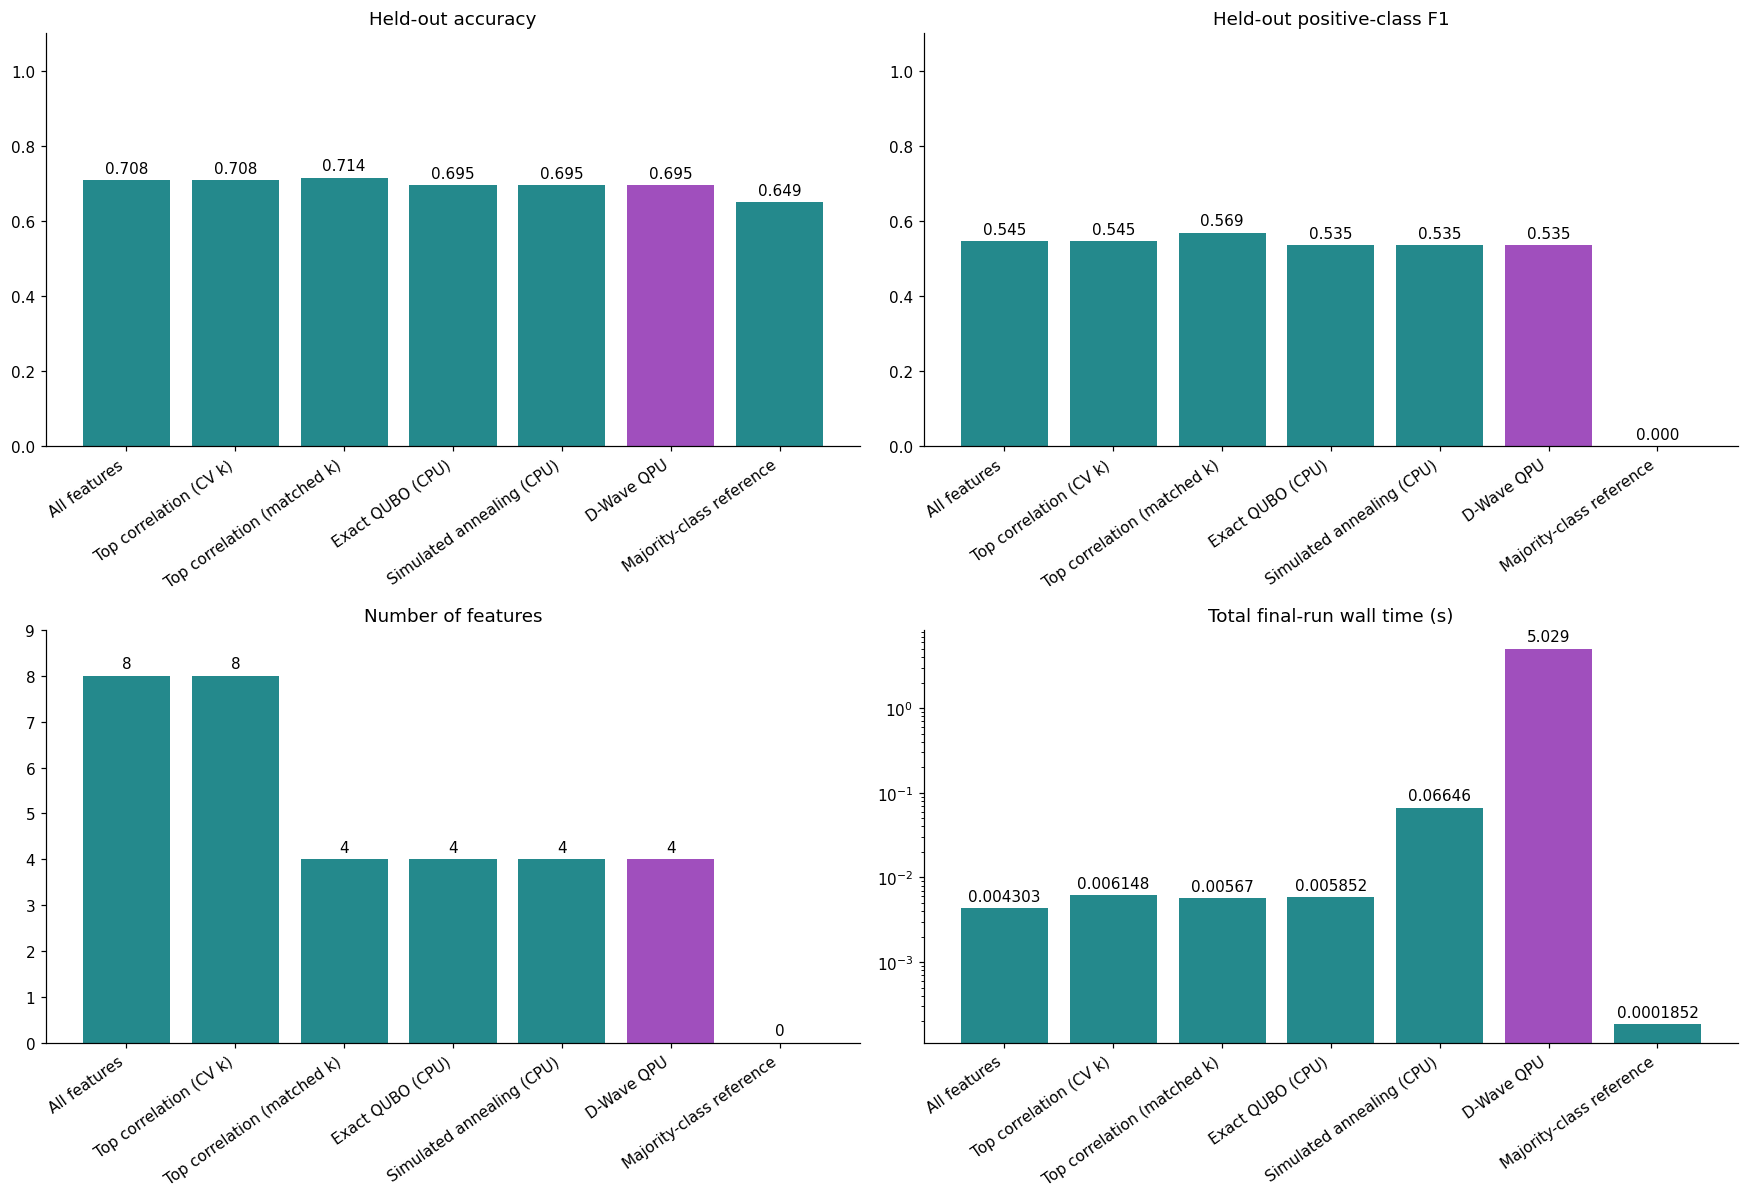

In [12]:
available = comparison.loc[comparison["status"].eq("evaluated")].copy()
labels = available["method"].tolist()
positions = np.arange(len(available))
colors = ["#a04fbd" if label == "D-Wave QPU" else "#24898c" for label in labels]
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, column, title in zip(axes.flat, ["accuracy", "f1", "num_features", "total_final_run_s"],
                            ["Held-out accuracy", "Held-out positive-class F1", "Number of features", "Total final-run wall time (s)"]):
    bars = ax.bar(positions, available[column], color=colors)
    ax.set_xticks(positions, labels, rotation=35, ha="right")
    ax.set_title(title)
    if column in ["accuracy", "f1"]:
        ax.set_ylim(0, 1.1)
        ax.bar_label(bars, fmt="%.3f", padding=3)
    elif column == "num_features":
        ax.set_ylim(0, 9)
        ax.bar_label(bars, fmt="%.0f", padding=3)
    else:
        ax.set_yscale("log")
        ax.bar_label(bars, labels=[f"{value:.4g}" for value in available[column]], padding=3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "classifier_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

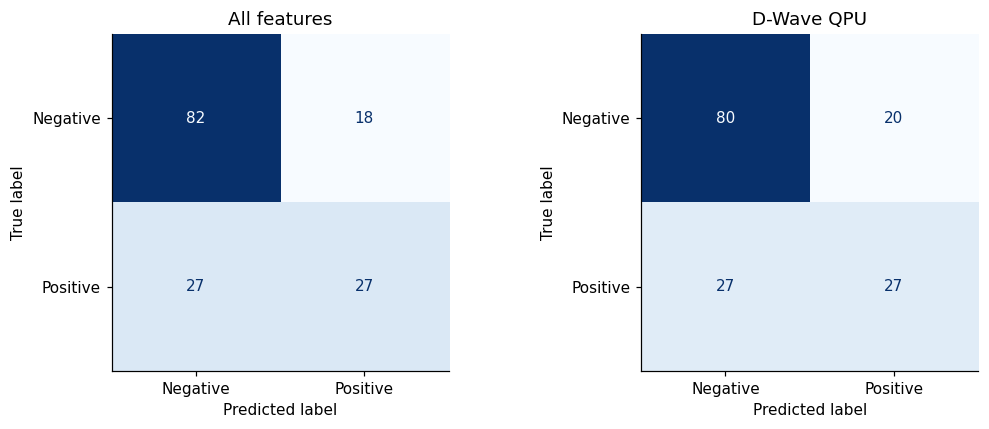

In [13]:
methods_to_plot = ["All features"]
if qpu_bits is not None:
    methods_to_plot.append("D-Wave QPU")
else:
    methods_to_plot.append("Exact QUBO (CPU)")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, method in zip(axes, methods_to_plot):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[method], display_labels=["Negative", "Positive"],
        ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set_title(method)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Separate QPU access time from end-to-end runtime

D-Wave timing fields are reported in microseconds. `qpu_access_time` includes device programming and sampling; it is not the same as `qpu_anneal_time_per_sample`, and it excludes important parts of client-observed elapsed time. The per-sample anneal field is not the total anneal time across all reads.

We convert each reported field individually and keep its original name. The full selection wall time is the comparison used above. [D-Wave timing documentation](https://docs.dwavequantum.com/en/latest/quantum_research/operation_timing.html)

In [14]:
timing_rows = [{"field": field, "microseconds": value, "seconds": value / 1_000_000}
               for field, value in qpu_metadata.get("timing_us", {}).items()
               if isinstance(value, (int, float))]
timing_table = pd.DataFrame(timing_rows, columns=["field", "microseconds", "seconds"])
display(timing_table)
if qpu_metadata.get("status") == "completed":
    print(f"Original QPU submission wall time: {qpu_metadata['solver_wall_s']:.6f} seconds")
print("Parameter-search wall time:", round(tuning_wall_s, 6), "seconds")

,field,microseconds,seconds
0,qpu_sampling_time,123440.00,0.123440
1,qpu_anneal_time_per_sample,20.00,0.000020
2,qpu_readout_time_per_sample,82.86,0.000083
3,qpu_access_time,139397.96,0.139398
4,qpu_access_overhead_time,715.04,0.000715
5,qpu_programming_time,15957.96,0.015958
6,qpu_delay_time_per_sample,20.58,0.000021
7,total_post_processing_time,1.00,0.000001
8,post_processing_overhead_time,1.00,0.000001


Original QPU submission wall time: 5.023165 seconds
Parameter-search wall time: 0.802969 seconds


## 10. What benefits can this experiment establish?

**Feature-selection benefits** can include fewer measurements and a simpler classifier while retaining useful predictive performance. Classical selectors can provide these benefits too; compare with top-correlation and CPU QUBO baselines before attributing any improvement to quantum computation.

**Potential quantum benefits** concern searching difficult binary optimization spaces as feature counts grow. Pairwise relevance/redundancy objectives can be submitted to an annealer, but feasibility on real hardware is not evidence of a computational advantage. Dense embeddings, analog precision, stochastic results, and cloud overhead all affect practical performance.

With only eight variables, a CPU enumerates 256 assignments cheaply. One dataset, one split, and one QPU job cannot establish quantum speedup, better generalization, or scalability. The exact solution supplies an objective benchmark. If the QPU and exact solver select the same features, identical predictions are expected from the same classifier pipeline.

The next cell writes a report using **the measured results**, including cases where the QPU is slower or unavailable. F1/accuracy differences on this small reused test split are descriptive, not evidence of statistical significance. Larger experiments should use repeated independent splits or nested validation, refit selection within folds, and compare strong classical optimizers under matched budgets.

In [15]:
baseline = comparison.loc[comparison.method.eq("All features")].iloc[0]
report_lines = [
    "# Pima correlation-QUBO experiment results", "",
    f"Dataset: 768 records; training={len(X_train_raw)}, test={len(X_test_raw)}; seed={RANDOM_STATE}.",
    f"Training-only five-fold selector tuning chose k={selected_k}, alpha={selected_alpha}; penalty A={penalty:.6f}.",
    "Classifier: median imputation + standardization + logistic regression (C=1; threshold=0.5).",
    "Objective: Pearson relevance–redundancy surrogate, not the reference paper's MI/CMI objective.", "",
    "| Method | Accuracy | Positive-class F1 | Features | Final-run wall time (s) |",
    "|---|---:|---:|---:|---:|",
]
for row in comparison.itertuples():
    if row.status == "evaluated":
        report_lines.append(f"| {row.method} | {row.accuracy:.4f} | {row.f1:.4f} | {int(row.num_features)} | {row.total_final_run_s:.6f} |")
    else:
        report_lines.append(f"| {row.method} (unavailable) | — | — | — | — |")
report_lines += ["", f"Parameter-search wall time: {tuning_wall_s:.6f} s, reported separately from final runs.",
                 "Final-run time includes selection, fit, and prediction; imports, file I/O, plots, and verification are excluded.", ""]
if qpu_bits is not None:
    quantum = comparison.loc[comparison.method.eq("D-Wave QPU")].iloc[0]
    exact_result = comparison.loc[comparison.method.eq("Exact QUBO (CPU)")].iloc[0]
    quantum_optimization = optimization_comparison.loc[optimization_comparison.method.eq("D-Wave QPU")].iloc[0]
    chosen_features = [FEATURES[i] for i in np.flatnonzero(qpu_bits)]
    report_lines += [
        "## Recorded hardware result", "",
        f"Solver: {qpu_metadata['solver']}; problem ID: {qpu_metadata['problem_id']}.",
        f"Reads: {qpu_metadata['num_reads_returned']}; physical qubits: {qpu_metadata['physical_qubits']}.",
        f"Selected features: {', '.join(chosen_features)}.",
        f"Feature reduction versus all predictors: {100 * (1 - quantum.num_features / 8):.1f}%.",
        f"Accuracy difference versus all features: {quantum.accuracy - baseline.accuracy:+.4f}.",
        f"F1 difference versus all features: {quantum.f1 - baseline.f1:+.4f}.",
        f"Best feasible QUBO energy gap from the exact optimum: {quantum_optimization.energy_gap:.8g}.",
        f"Observed exact-optimum-read fraction: {quantum_optimization.exact_optimum_read_fraction:.4f}.",
        f"Same subset as the exact solver: {bool(np.array_equal(qpu_bits, exact_bits))}.",
        f"Original QPU final-run wall time: {quantum.total_final_run_s:.6f} s; CPU exact-QUBO final-run wall time: {exact_result.total_final_run_s:.6f} s.",
        f"This notebook loaded cached hardware samples: {qpu_metadata.get('loaded_from_cache', False)}.",
    ]
    access_time = qpu_metadata.get("timing_us", {}).get("qpu_access_time")
    if access_time is not None:
        report_lines.append(f"Reported QPU access time: {access_time / 1_000_000:.6f} s; this excludes cloud/client overhead.")
    if quantum.total_final_run_s >= exact_result.total_final_run_s:
        report_lines.append("The QPU did not provide an end-to-end runtime advantage over exact CPU selection in this run.")
    else:
        report_lines.append("The QPU's measured final-run time was lower in this run; controlled repeated benchmarks are still required before claiming speedup.")
else:
    report_lines += ["Hardware classification result unavailable.", f"Hardware status: {qpu_metadata.get('status')}."]
report_lines += ["", "## Interpretation", "",
                 "Smaller subsets and competitive predictive scores are benefits of feature selection; they are not automatically quantum-specific benefits.",
                 "This eight-variable experiment demonstrates implementation and, when completed, real hardware execution. It does not establish quantum advantage.",
                 "One reused held-out split and one QPU job provide descriptive results only; do not infer significance, clinical validity, or scalability.", "",
                 "References: [D-Wave sampling](https://docs.dwavequantum.com/en/latest/ocean/api_ref_system/samplers.html), "
                 "[D-Wave timing](https://docs.dwavequantum.com/en/latest/quantum_research/operation_timing.html), "
                 "[preventing leakage](https://scikit-learn.org/stable/common_pitfalls.html).", ""]
report = "\n".join(report_lines)
display(Markdown(report))

# Pima correlation-QUBO experiment results

Dataset: 768 records; training=614, test=154; seed=42.
Training-only five-fold selector tuning chose k=4, alpha=0.5; penalty A=1.199366.
Classifier: median imputation + standardization + logistic regression (C=1; threshold=0.5).
Objective: Pearson relevance–redundancy surrogate, not the reference paper's MI/CMI objective.

| Method | Accuracy | Positive-class F1 | Features | Final-run wall time (s) |
|---|---:|---:|---:|---:|
| All features | 0.7078 | 0.5455 | 8 | 0.004303 |
| Top correlation (CV k) | 0.7078 | 0.5455 | 8 | 0.006148 |
| Top correlation (matched k) | 0.7143 | 0.5686 | 4 | 0.005670 |
| Exact QUBO (CPU) | 0.6948 | 0.5347 | 4 | 0.005852 |
| Simulated annealing (CPU) | 0.6948 | 0.5347 | 4 | 0.066461 |
| D-Wave QPU | 0.6948 | 0.5347 | 4 | 5.028625 |
| Majority-class reference | 0.6494 | 0.0000 | 0 | 0.000185 |

Parameter-search wall time: 0.802969 s, reported separately from final runs.
Final-run time includes selection, fit, and prediction; imports, file I/O, plots, and verification are excluded.

## Recorded hardware result

Solver: Advantage_system6;graph_id=01dae5a273; problem ID: efc6b6f3-0166-4eda-876d-19006bc1fb8c.
Reads: 1000; physical qubits: 12.
Selected features: Pregnancies, Glucose, BMI, DiabetesPedigreeFunction.
Feature reduction versus all predictors: 50.0%.
Accuracy difference versus all features: -0.0130.
F1 difference versus all features: -0.0108.
Best feasible QUBO energy gap from the exact optimum: 0.
Observed exact-optimum-read fraction: 0.0370.
Same subset as the exact solver: True.
Original QPU final-run wall time: 5.028625 s; CPU exact-QUBO final-run wall time: 0.005852 s.
This notebook loaded cached hardware samples: False.
Reported QPU access time: 0.139398 s; this excludes cloud/client overhead.
The QPU did not provide an end-to-end runtime advantage over exact CPU selection in this run.

## Interpretation

Smaller subsets and competitive predictive scores are benefits of feature selection; they are not automatically quantum-specific benefits.
This eight-variable experiment demonstrates implementation and, when completed, real hardware execution. It does not establish quantum advantage.
One reused held-out split and one QPU job provide descriptive results only; do not infer significance, clinical validity, or scalability.

References: [D-Wave sampling](https://docs.dwavequantum.com/en/latest/ocean/api_ref_system/samplers.html), [D-Wave timing](https://docs.dwavequantum.com/en/latest/quantum_research/operation_timing.html), [preventing leakage](https://scikit-learn.org/stable/common_pitfalls.html).


## 11. Save the experiment artifacts and validate consistency

Outputs include per-fold tuning scores, final classifier metrics, selected subsets, predictions indexed by original record IDs, solver diagnostics, the exact QUBO specification, and the recorded QPU response. Credentials and fitted model objects are not exported.

Part 1's outputs and user-edited notebook are preserved. The artifacts here are saved in `outputs/qubo/`.

In [16]:
cv_details.to_csv(OUTPUT_DIR / "qubo_cv_folds.csv", index=False)
cv_summary.to_csv(OUTPUT_DIR / "qubo_cv_summary.csv", index=False)
pd.DataFrame(topk_cv_rows).to_csv(OUTPUT_DIR / "topk_cv_folds.csv", index=False)
topk_cv_summary.to_csv(OUTPUT_DIR / "topk_cv_summary.csv", index=False)
pd.DataFrame(all_features_cv_rows).to_csv(OUTPUT_DIR / "all_features_cv_folds.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "classifier_comparison.csv", index=False)
optimization_comparison.to_csv(OUTPUT_DIR / "solver_comparison.csv", index=False)
subset_comparison.to_csv(OUTPUT_DIR / "selected_subsets.csv", index=False)
timing_table.to_csv(OUTPUT_DIR / "qpu_timing.csv", index=False)
Q_display.to_csv(OUTPUT_DIR / "qubo_upper_triangle.csv", index_label="feature")
samples_frame(exact_samples).to_csv(OUTPUT_DIR / "exact_samples.csv", index=False)
samples_frame(sa_samples).to_csv(OUTPUT_DIR / "simulated_annealing_samples.csv", index=False)
prediction_frame = pd.DataFrame({"Outcome": y_test})
for method, prediction in predictions.items():
    prediction_frame[method] = prediction
prediction_frame.to_csv(OUTPUT_DIR / "test_predictions.csv", index_label="record_id")
split_frame = pd.DataFrame({"partition": "train"}, index=X_train_raw.index)
split_frame = pd.concat([split_frame, pd.DataFrame({"partition": "test"}, index=X_test_raw.index)]).sort_index()
split_frame.to_csv(OUTPUT_DIR / "split_indices.csv", index_label="record_id")
(OUTPUT_DIR / "results.md").write_text(report)
save_json(OUTPUT_DIR / "experiment_metadata.json", {
    "source_sha256": EXPECTED_SHA256, "feature_order": FEATURES,
    "random_state": RANDOM_STATE, "test_size": TEST_SIZE, "cv_folds": CV_FOLDS,
    "k_grid": K_VALUES, "alpha_grid": ALPHA_VALUES,
    "chosen_k": selected_k, "chosen_alpha": selected_alpha, "penalty": penalty,
    "topk_baseline_chosen_k": topk_selected_k,
    "primary_tuning_metric": "positive-class F1", "classifier_C": 1.0,
    "decision_threshold": 0.5, "training_rows": len(X_train_raw), "test_rows": len(X_test_raw),
    "tuning_wall_s": tuning_wall_s, "score_preparation_s": score_preparation_s,
    "qubo_build_s": qubo_build_s, "num_reads": NUM_READS, "sa_num_sweeps": 1000,
    "qpu_status": qpu_metadata.get("status"), "qpu_fingerprint": fingerprint,
    "versions": VERSIONS, "cpu_math_threads": 1,
    "runtime_scope": "Final selection + model fit + prediction; parameter search recorded separately",
    "limitations": "One small dataset, a previously explored test split, one QPU job; no quantum advantage claim",
})

assert comparison.loc[comparison.status.eq("evaluated"), "accuracy"].between(0, 1).all()
assert comparison.loc[comparison.status.eq("evaluated"), "f1"].between(0, 1).all()
assert prediction_frame.index.equals(y_test.index)
for method in ["Exact QUBO (CPU)", "Simulated annealing (CPU)", "D-Wave QPU"]:
    bits = selected_subsets[method]
    if bits is not None:
        assert int(bits.sum()) == selected_k
        energy = bqm.energy(dict(enumerate(bits)))
        assert energy >= exact_optimum - 1e-8
        if np.array_equal(bits, exact_bits):
            np.testing.assert_array_equal(predictions[method], predictions["Exact QUBO (CPU)"])

print("All QUBO, subset, prediction, and metric checks passed.")
print("Saved results:", OUTPUT_DIR)
print("Hardware status:", qpu_metadata.get("status"))

All QUBO, subset, prediction, and metric checks passed.
Saved results: /Users/maishachowa/Maisha/Research/Quantum-Computing/Quantum annealing for feature selection/outputs/qubo
Hardware status: completed


## Study questions

1. Why do relevance coefficients have negative signs in an energy minimization problem?
2. What happens to the size penalty when the sample contains $k+1$ rather than $k$ selected features?
3. Why can the QUBO's optimal subset differ from the top-$k$ individual correlations?
4. Why should a QPU-selected subset and an exact-CPU-selected identical subset have the same classifier predictions?
5. Which runtime includes network and queue delays? Which timing field is measured on the device?
6. Which benefits in the results come from selecting features, and what additional experiments would support a quantum-specific benefit?